# SRF heterodyne cavities (beta)

In superconducting radio-frequency (SRF) heterodyne experiments, a cavity drives a pump mode whose oscillating magnetic field converts axions into a nearby signal mode. In this tutorial we tune their frequency difference to the axion frequency and calculate mode overlap, scan sensitivity and vibration limits.

> **Beta.** The `axionfem.srf` and `axionfem.heterodyne` modules are beta in this release: they are checked against closed-form cylinder results and the published cell geometry, but their interfaces may still change.

## Mode overlap and size

The overlap amplitude and dimensionless pump frequency are

$$
\eta_{10}=\frac{\left|\int_V\widetilde{\mathbf E}_1^*\cdot\widetilde{\mathbf B}_0\,dV\right|}
{\left(\int_V|\widetilde{\mathbf E}_1|^2\,dV\int_V|\widetilde{\mathbf B}_0|^2\,dV\right)^{1/2}},
\qquad \xi=\frac{\omega_0 V^{1/3}}{c}.
$$

$V$ includes beam-tube stubs, $\omega_0$ is angular pump frequency, $c$ is light speed, and tildes denote mode amplitudes. Both quantities are unchanged by uniform scaling.

In [1]:
import json, math, tempfile
from pathlib import Path

import numpy as np
import scipy.optimize, scipy.integrate                                      # noqa: F401
from scipy.special import jn_zeros, jnp_zeros
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import NullFormatter

import axionfem as af
from axionfem import srf, heterodyne as het
from axionfem.circuit import HBAR

print("axionFEM", af.__version__)
MU0, C, Z0 = srf.MU0, srf.C_LIGHT, srf.Z0
CELL = srf.PROJECTX_650_B09                       # Project X 650 MHz cell, unshortened [m]
REQ = CELL["equator_radius"]
RUNS = Path(tempfile.mkdtemp(prefix="axf_srf_"))   # solver run directories
ROOT = Path.cwd().parent                          # repository root when run from examples/
plt.rcParams.update({"figure.dpi": 80, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"


def solve(design, tag, **kw):
    """Solve in RUNS/tag and report the number of unknowns and any solver warning."""
    r = design.solve(RUNS / tag, verbose=0, **kw)
    # the cavity designs carry a nominal 1 T background field (for the form factor C, unused here): drop its warning
    w = [x for x in (r.data.get("warnings") or []) if "background field is present" not in x]
    print(f"  {tag}: {r.data.get('mesh', {}).get('dofs')} DOFs" + (f", warnings: {w}" if w else ""))
    return r


def rel(a, b):
    return a / b - 1.0

axionFEM 0.1.0


## Closed cylinders

We compare axisymmetric solves with analytic results for three degenerate mode pairs.

In [2]:
PAIRS = ("TM020/TE011", "TM030/TE021", "TE012/TM013")
KEYS = [("xi", "xi_pump", "xi"), ("eta_10", "eta_10", "eta_10"), ("B_pk/B0 (pump)", "Bpk_over_B0", "Bpk_over_B0"),
        ("E_pk/(c B0) (pump)", "Epk_over_cB0", "Epk_over_cB0"), ("G pump [ohm]", "G_pump_ohm", "G_pump_ohm"),
        ("G signal [ohm]", "G_signal_ohm", "G_signal_ohm"), ("A/V^(2/3)", "A_over_V23", "A_over_V23")]
cyl = {}
for pair in PAIRS:
    pump, signal = pair.split("/")
    ana = srf.cylinder_pair(pair)
    dc = srf.cylinder_pair_design(pair, 0.10, h=0.10 / 20, order=3, modes=6)
    rc = solve(dc, "cyl_" + pump)
    num = srf.figures_of_merit(rc, pump, signal)
    cyl[pair] = dict(ana=ana, num=num, design=dc, res=rc)

for pair, c in cyl.items():
    ana, num = c["ana"], c["num"]
    f_deg = c["design"].srf_contour["params"]["f_degenerate_Hz"]
    print(f"\n{pair}:  L/R = {ana['L_over_R']:.5f},  "
          f"f = {f_deg / 1e9:.6f} GHz at R = 10 cm;  solver f_pump/f_deg - 1 = {rel(num['f_pump_Hz'], f_deg):+.1e}, "
          f"f_signal/f_deg - 1 = {rel(num['f_signal_Hz'], f_deg):+.1e}")
    print(f"  {'':20s}{'closed form':>13s}{'2D solve':>12s}{'rel. diff':>11s}")
    for lab, kn, ka in KEYS:
        a, n = ana[ka], num[kn]
        d = f"{rel(n, a):+11.1e}" if abs(a) > 1e-9 else f"{'(both 0)':>11s}"
        print(f"  {lab:20s}{a:13.5f}{n:12.5f}{d}")

  cyl_TM020: 17245 DOFs
  cyl_TM030: 16951 DOFs
  cyl_TE012: 24697 DOFs

TM020/TE011:  L/R = 0.79062,  f = 2.633820 GHz at R = 10 cm;  solver f_pump/f_deg - 1 = +3.8e-10, f_signal/f_deg - 1 = +4.4e-10
                        closed form    2D solve  rel. diff
  xi                        7.47569     7.47569   +3.8e-10
  eta_10                    0.43697     0.43702   +9.8e-05
  B_pk/B0 (pump)            1.71004     1.70999   -2.8e-05
  E_pk/(c B0) (pump)        2.93889     2.93890   +4.8e-06
  G pump [ohm]            459.10348   459.10347   -6.8e-09
  G signal [ohm]          580.03894   580.03894   -4.3e-09
  A/V^(2/3)                 6.13439     6.13439   +8.9e-16

TM030/TE021:  L/R = 0.62008,  f = 4.128992 GHz at R = 10 cm;  solver f_pump/f_deg - 1 = +6.8e-09, f_signal/f_deg - 1 = +8.0e-09
                        closed form    2D solve  rel. diff
  xi                       10.80777    10.80777   +6.8e-09
  eta_10                    0.49214     0.49220   +1.2e-04
  B_pk/B0 (pump)     

We compare the closed-form overlaps with `srf.cylinder_pair` and the axisymmetric solves to check agreement.

In [3]:
# Closed-form overlaps; a_n and b_n are zeros of J0 and J1.
a, b = jn_zeros(0, 3), jnp_zeros(0, 2)            # jnp_zeros(0, n) = zeros of J0' = -J1
closed = {"TM020/TE011": 4 * math.sqrt(2) * b[0] / (math.pi * (a[1] ** 2 - b[0] ** 2)),
          "TM030/TE021": 4 * math.sqrt(2) * b[1] / (math.pi * (a[2] ** 2 - b[1] ** 2)),
          "TE012/TM013": 16 * b[0] / (5 * math.pi * (b[0] ** 2 - a[0] ** 2))}
for pair, eta in closed.items():
    print(f"{pair}: eta_10 closed form {eta:.8f}, srf.cylinder_pair {cyl[pair]['ana']['eta_10']:.8f}, "
          f"2D solve {cyl[pair]['num']['eta_10']:.8f}")

TM020/TE011: eta_10 closed form 0.43697304, srf.cylinder_pair 0.43697304, 2D solve 0.43701608
TM030/TE021: eta_10 closed form 0.49213898, srf.cylinder_pair 0.49213898, 2D solve 0.49219741
TE012/TM013: eta_10 closed form 0.43859289, srf.cylinder_pair 0.43859289, 2D solve 0.43860585


## Elliptical cell

We compare the original Project X contour with a shortened contour chosen to bring TM020 and TE011 together.

unshortened  V = 19.585 L (tubes included), A = 0.4317 m^2, length 407.6 mm, wall angle 5.25 deg, 345 wall vertices
x 0.86       V = 17.063 L (tubes included), A = 0.4097 m^2, length 378.5 mm, wall angle 4.52 deg, 331 wall vertices
tangent points (z, r) [mm] of the x 0.86 cell: [(-74.07, 80.76), (-70.64, 124.13)]


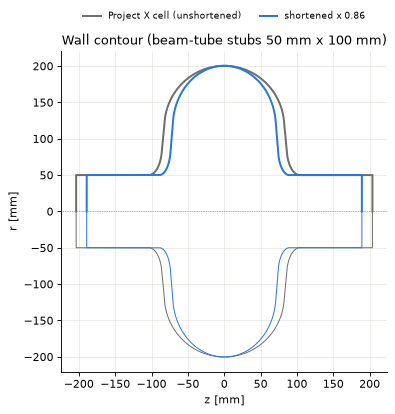

In [4]:
con0 = srf.elliptical_cell_contour(CELL, axial_factor=1.0)
con = srf.elliptical_cell_contour(CELL, axial_factor=0.86)
for name, c in (("unshortened", con0), ("x 0.86", con)):
    p = c["params"]
    print(f"{name:12s} V = {c['V_m3'] * 1e3:6.3f} L (tubes included), A = {c['A_m2']:.4f} m^2, length {c['length'] * 1e3:.1f} mm, "
          f"wall angle {c['tangent_angle_deg']:.2f} deg, {len(c['wall'])} wall vertices")
print("tangent points (z, r) [mm] of the x 0.86 cell:", [tuple(round(1e3 * v, 2) for v in q) for q in con["params"]["tangent_points_zr"]])

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for c, col, lab in ((con0, GREY, "Project X cell (unshortened)"), (con, BLUE, "shortened x 0.86")):
    W = np.array(c["wall"])
    ax.plot(W[:, 1] * 1e3, W[:, 0] * 1e3, color=col, label=lab)
    ax.plot(W[:, 1] * 1e3, -W[:, 0] * 1e3, color=col, lw=0.9)
ax.axhline(0, color=GREY, lw=0.6, ls=":")
ax.set_aspect("equal"); ax.set_xlabel("z [mm]"); ax.set_ylabel("r [mm]")
ax.set_title("Wall contour (beam-tube stubs 50 mm x 100 mm)"); ax.legend(loc="lower center", fontsize=8,
                                                                      bbox_to_anchor=(0.5, 1.07), ncol=2)
plt.show()

### Tuning the splitting

We sweep the axial factor to locate the frequency crossing.

tuner: axial factor 0.86002, f = 1.41651 GHz (7 solves)
d[(f_TE011 - f_TM020)/f]/ds = -0.570 per unit axial factor: a 1 % change of the splitting needs ds = 0.0175


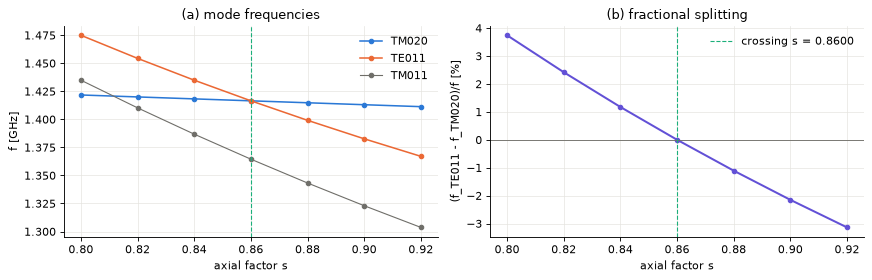

In [5]:
COARSE = {"h": REQ / 20, "order": 2, "modes": 6}
sweep = []
for s in np.round(np.arange(0.80, 0.921, 0.02), 3):
    d = srf.elliptical_cell_design(CELL, axial_factor=float(s), **COARSE)
    r = d.solve(RUNS / f"sweep_{s}", verbose=0)
    lab = srf.classify_modes(r, d.srf_contour)
    row = {"s": float(s)}
    for nm in ("TM020", "TE011", "TM011"):
        hit = [m for m in lab if m["name"] == nm]
        row[nm] = hit[0]["f_Hz"] if len(hit) == 1 else np.nan
    sweep.append(row)
tune = srf.tune_degeneracy("TM020", "TE011", cell=CELL, bracket=(0.84, 0.88), tol=2e-5, design_kw=COARSE,
                           workdir=str(RUNS / "tuner"))
print(f"tuner: axial factor {tune['axial_factor']:.5f}, f = {tune['f_Hz'] / 1e9:.5f} GHz "
      f"({len(tune['history'])} solves)")
# slope of the fractional splitting at the crossing: linear fit through the sweep points 0.84, 0.86, 0.88
near = [x for x in sweep if 0.835 < x["s"] < 0.885]
slope = np.polyfit([x["s"] for x in near], [(x["TE011"] - x["TM020"]) / x["TM020"] for x in near], 1)[0]
print(f"d[(f_TE011 - f_TM020)/f]/ds = {slope:.3f} per unit axial factor: a 1 % change of the splitting needs "
      f"ds = {0.01 / abs(slope):.4f}")

S = np.array([x["s"] for x in sweep])
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 3.6))
for nm, col in (("TM020", BLUE), ("TE011", ORANGE), ("TM011", GREY)):
    ax0.plot(S, [x[nm] / 1e9 for x in sweep], "o-", color=col, ms=4, label=nm, lw=1.4 if nm != "TM011" else 1.0)
ax0.axvline(tune["axial_factor"], color=GREEN, lw=1, ls="--")
ax0.set_xlabel("axial factor s"); ax0.set_ylabel("f [GHz]"); ax0.legend(); ax0.set_title("(a) mode frequencies")
split = np.array([(x["TE011"] - x["TM020"]) / x["TM020"] for x in sweep])
ax1.plot(S, 100 * split, "o-", color=VIOLET, ms=4)
ax1.axhline(0, color=GREY, lw=0.8); ax1.axvline(tune["axial_factor"], color=GREEN, lw=1, ls="--",
                                                 label=f"crossing s = {tune['axial_factor']:.4f}")
ax1.set_xlabel("axial factor s"); ax1.set_ylabel("(f_TE011 - f_TM020)/f [%]"); ax1.legend()
ax1.set_title("(b) fractional splitting")
fig.tight_layout(); plt.show()

The slope estimates the deformation needed to scan; no mechanical tuner is modeled.

### Mode solve

We solve the modes to inspect their labels, frequencies and residuals.

In [6]:
dcell = srf.elliptical_cell_design(CELL, axial_factor=0.86, h=REQ / 40, order=3, modes=6)
rcell = solve(dcell, "cell_n40_o3")
labels = srf.classify_modes(rcell, dcell.srf_contour)
print(f"{'mode':7s}{'f [GHz]':>11s}{'G [ohm]':>10s}{'residual':>11s}")
for m in labels:
    print(f"{m['name']:7s}{m['f_Hz'] / 1e9:11.6f}{m['G_ohm']:10.2f}{m['residual_true']:11.1e}")

  cell_n40_o3: 105238 DOFs
mode       f [GHz]   G [ohm]   residual
TM010     0.649550    231.40    7.1e-11
TM011     1.364506    350.93    2.3e-12
TM020     1.416510    524.47    1.2e-12
TE011     1.416531    604.48    7.0e-13
TM021     1.942838    519.52    2.8e-12
TE021     2.027390   1138.99    1.0e-11
TM030     2.094487    631.09    5.6e-12
TE012     2.276414    803.33    3.1e-12
TM012     2.285543    607.62    1.2e-11
TE031     2.702482   1688.04    1.9e-11
TE022     2.731251   1157.60    3.7e-12
TE013     3.139762   1082.10    1.2e-12


### Geometry factors

`srf.figures_of_merit` returns overlap, frequencies (Hz) and geometry factors (ohms).

We compute these quantities and field peaks to characterize the mode pair.

In [7]:
fom = srf.figures_of_merit(rcell, "TM020", "TE011")
rows = [("f TM020 [GHz]", "f_pump_Hz", 1e-9), ("f TE011 [GHz]", "f_signal_Hz", 1e-9), ("V [L]", "V_m3", 1e3),
        ("xi", "xi_pump", 1), ("eta_10", "eta_10", 1), ("B_pk/B0 (wall max)", "Bpk_over_B0", 1),
        ("B/B0 at the equator", "B_equator_over_B0", 1), ("E_pk/(c B0)", "Epk_over_cB0", 1),
        ("A/V^(2/3)", "A_over_V23", 1), ("G pump [ohm]", "G_pump_ohm", 1), ("G signal [ohm]", "G_signal_ohm", 1)]
print(f"{'quantity':22s}{'value':>13s}")
for lab, k, u in rows:
    print(f"{lab:22s}{fom[k] * u:13.6g}")
print(f"\nsplitting f_TE011 - f_TM020 = {fom['splitting_Hz'] / 1e3:.1f} kHz ({fom['splitting_Hz'] / fom['f_pump_Hz']:.1e} of f)")
print(f"eta_10^2 = {fom['eta_10_squared']:.4f}")
print("B_pk at (r, z) =", tuple(round(1e3 * v, 1) for v in fom["pump_peaks"]["Bpk_at_rz"]), "mm;  E_pk at (r, z) =",
      tuple(round(1e3 * v, 1) for v in fom["pump_peaks"]["Epk_at_rz"]), "mm")
print("checks:", {k: (round(v, 6) if isinstance(v, float) else v) for k, v in fom["checks"].items()})

quantity                      value
f TM020 [GHz]               1.41651
f TE011 [GHz]               1.41653
V [L]                       17.0628
xi                          7.64298
eta_10                     0.449217
B_pk/B0 (wall max)            1.464
B/B0 at the equator         1.40394
E_pk/(c B0)                 1.84516
A/V^(2/3)                   6.18223
G pump [ohm]                524.474
G signal [ohm]              604.478

splitting f_TE011 - f_TM020 = 20.3 kHz (1.4e-05 of f)
eta_10^2 = 0.2018
B_pk at (r, z) = (77.7, -74.4) mm;  E_pk at (r, z) = (52.8, -83.5) mm
checks: {'int_E1^2 (1 expected)': 0.999859, 'int_E0^2 (1 expected)': 0.999881, 'c^2 int B0^2 (1 expected at resonance)': 0.999881, 'c^2 int B1^2 (1 expected)': 0.999883, 'n_wall_points': 2905, 'subdiv': 4, 'volume_contour_vs_solver': -0.0}


We use the wall maximum for $B_{\rm pk}$; the equator is a diagnostic. $B_0$ is spatial rms, peak in time. The wall contour and mesh should be refined for peak fields, especially electric peaks, normalized by $cB_0$.

### Meridional fields

Opposite signs of the overlap density cancel in the volume integral.

We plot the mode fields and compare cell and cylinder overlap densities to show these cancellations.

volume average of the overlap density: 0.44907  (eta_10 = 0.44922)


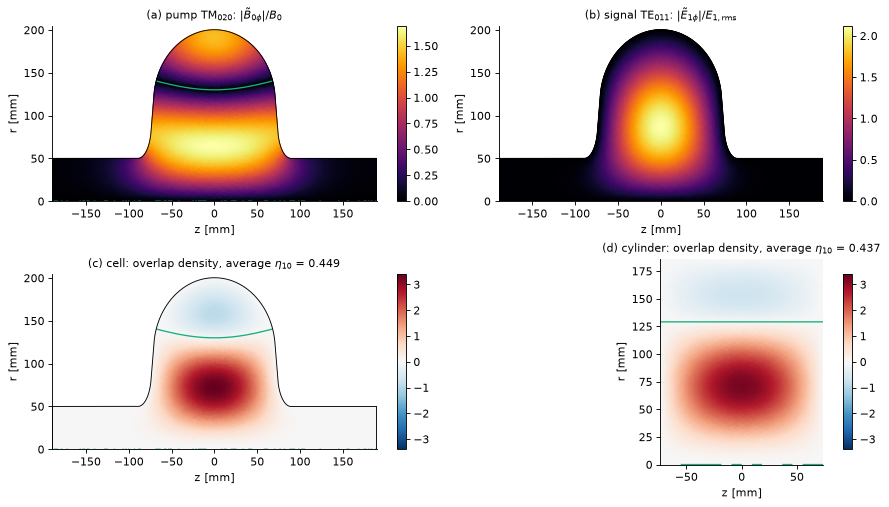

In [8]:
pr, sg = srf.find_mode(rcell, "TM020", labels=labels), srf.find_mode(rcell, "TE011", labels=labels)
Fp, Fs = rcell.cavity_mode_field(pr, subdiv=2), rcell.cavity_mode_field(sg, subdiv=2)
V = fom["V_m3"]
B0rms = fom["pump_peaks"]["B_rms"]
E1rms = math.sqrt(fom["checks"]["int_E1^2 (1 expected)"] / V)
Bphi, Ephi = MU0 * Fp["H_phi"] / B0rms, Fs["E_phi"] / E1rms
ov = Bphi * Ephi
sgn = np.sign(srf._tri_product_integral(Fp["r"], Fp["z"], Fp["tris"], Bphi, Ephi))
print(f"volume average of the overlap density: {sgn * srf._tri_product_integral(Fp['r'], Fp['z'], Fp['tris'], Bphi, Ephi) / V:.5f}"
      f"  (eta_10 = {fom['eta_10']:.5f})")
ov = sgn * ov

ccyl = cyl["TM020/TE011"]
rc = ccyl["res"]; lc = srf.classify_modes(rc, ccyl["design"].srf_contour)
pc, sc_ = srf.find_mode(rc, "TM020", labels=lc), srf.find_mode(rc, "TE011", labels=lc)
Gp, Gs = rc.cavity_mode_field(pc, subdiv=2), rc.cavity_mode_field(sc_, subdiv=2)
Vc = ccyl["num"]["V_m3"]
Bc = MU0 * Gp["H_phi"] / ccyl["num"]["pump_peaks"]["B_rms"]
Ec = Gs["E_phi"] / math.sqrt(ccyl["num"]["checks"]["int_E1^2 (1 expected)"] / Vc)
ovc = Bc * Ec * np.sign(srf._tri_product_integral(Gp["r"], Gp["z"], Gp["tris"], Bc, Ec))
kscale = ccyl["num"]["f_pump_Hz"] / fom["f_pump_Hz"]          # cylinder lengths x this -> same frequency as the cell

Wc = np.array(dcell.srf_contour["wall"])
fig, axs = plt.subplots(2, 2, figsize=(11.5, 6.4))
panels = [(axs[0, 0], Fp, np.abs(Bphi), "inferno", r"(a) pump TM$_{020}$: $|\tilde B_{0\phi}|/B_0$", 1.0),
          (axs[0, 1], Fs, np.abs(Ephi), "inferno", r"(b) signal TE$_{011}$: $|\tilde E_{1\phi}|/E_{1,\rm rms}$", 1.0),
          (axs[1, 0], Fp, ov, "RdBu_r", r"(c) cell: overlap density, average $\eta_{10}$" + f" = {fom['eta_10']:.3f}", 1.0),
          (axs[1, 1], Gp, ovc, "RdBu_r", r"(d) cylinder: overlap density, average $\eta_{10}$" + f" = {ccyl['num']['eta_10']:.3f}",
           kscale)]
lim = max(np.abs(ov).max(), np.abs(ovc).max())
ze, rmax = dcell.srf_contour["z_end"] * 1e3, REQ * 1e3
for ax, F, val, cmap, title, s in panels:
    kw = dict(norm=TwoSlopeNorm(0, -lim, lim)) if cmap == "RdBu_r" else {}
    im = ax.tripcolor(F["z"] * s * 1e3, F["r"] * s * 1e3, F["tris"], val, cmap=cmap, shading="gouraud", rasterized=True, **kw)
    fig.colorbar(im, ax=ax, shrink=0.85)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal"); ax.grid(False)
    if F is Fp or F is Fs:
        ax.set_xlim(-ze, ze); ax.set_ylim(0, rmax * 1.02)
    ax.set_xlabel("z [mm]"); ax.set_ylabel("r [mm]")
for ax, F, B in ((axs[0, 0], Fp, Bphi), (axs[1, 0], Fp, Bphi), (axs[1, 1], Gp, Bc)):
    s = kscale if F is Gp else 1.0
    ax.tricontour(F["z"] * s * 1e3, F["r"] * s * 1e3, F["tris"], B, levels=[0.0], colors=GREEN, linewidths=1.2)
for ax in axs[0, 0], axs[0, 1], axs[1, 0]:
    ax.plot(Wc[:, 1] * 1e3, Wc[:, 0] * 1e3, color="k", lw=0.8)
fig.tight_layout(); plt.show()

### Equator fields

The green circle marks the pump field's sign reversal.

We plot the equator fields and overlap density to show their radial structure.

pump sign-reversal radius at z = 0: r = 130.1 mm = 0.650 R_eq


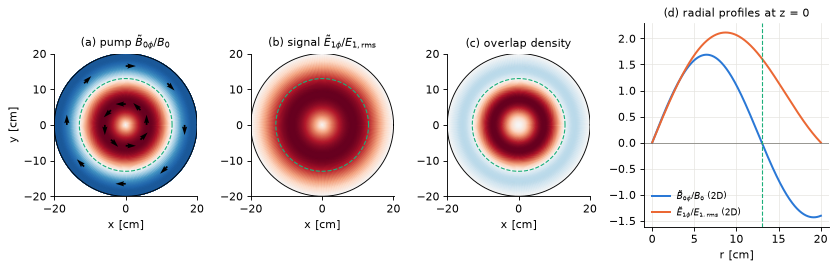

In [9]:
rr = np.linspace(1e-6, 1 - 1e-6, 801) * REQ
lp, ls = rcell.cavity_mode_sample(pr, rr, 0 * rr), rcell.cavity_mode_sample(sg, rr, 0 * rr)
Bl, El = MU0 * lp["H_phi"] / B0rms, sgn * ls["E_phi"] / E1rms
i0 = np.nonzero(np.diff(np.sign(Bl)))[0][0]
r_node = float(np.interp(0.0, [Bl[i0 + 1], Bl[i0]], [rr[i0 + 1], rr[i0]]))
print(f"pump sign-reversal radius at z = 0: r = {r_node * 1e3:.1f} mm = {r_node / REQ:.3f} R_eq")

R, T = np.meshgrid(rr, np.linspace(0, 2 * np.pi, 241))
X, Y = R * np.cos(T), R * np.sin(T)
fig = plt.figure(figsize=(12.5, 3.3))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.3], wspace=0.35)
th = np.linspace(0, 2 * np.pi, 300)
for k, (prof, title) in enumerate(((Bl, r"(a) pump $\tilde B_{0\phi}/B_0$"), (El, r"(b) signal $\tilde E_{1\phi}/E_{1,\rm rms}$"),
                                   (Bl * El, r"(c) overlap density"))):
    ax = fig.add_subplot(gs[0, k])
    F = np.interp(R, rr, prof)
    m = np.abs(F).max()
    ax.pcolormesh(X * 100, Y * 100, F, cmap="RdBu_r", norm=TwoSlopeNorm(0, -m, m), shading="gouraud", rasterized=True)
    ax.plot(REQ * 100 * np.cos(th), REQ * 100 * np.sin(th), color="k", lw=0.8)
    ax.plot(r_node * 100 * np.cos(th), r_node * 100 * np.sin(th), color=GREEN, lw=1.0, ls="--")
    if k == 0:                                   # circulation arrows of the pump field
        for rq in (0.45 * r_node, 0.5 * (r_node + REQ)):
            for t in np.linspace(0, 2 * np.pi, 8, endpoint=False):
                v = float(np.interp(rq, rr, Bl))
                ax.quiver(rq * 100 * np.cos(t), rq * 100 * np.sin(t), -np.sin(t) * np.sign(v), np.cos(t) * np.sign(v),
                          scale=14, width=0.012, color="k")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10); ax.grid(False); ax.set_xlabel("x [cm]")
    if k == 0:
        ax.set_ylabel("y [cm]")
ax = fig.add_subplot(gs[0, 3])
ax.plot(rr * 100, Bl, color=BLUE, label=r"$\tilde B_{0\phi}/B_0$ (2D)")
ax.plot(rr * 100, El, color=ORANGE, label=r"$\tilde E_{1\phi}/E_{1,\rm rms}$ (2D)")
ax.axhline(0, color=GREY, lw=0.6); ax.axvline(r_node * 100, color=GREEN, lw=1, ls="--")
ax.set_xlabel("r [cm]"); ax.set_title("(d) radial profiles at z = 0", fontsize=10); ax.legend(fontsize=8)
plt.show()

### Wall fields

We plot the wall fields to locate their maxima.

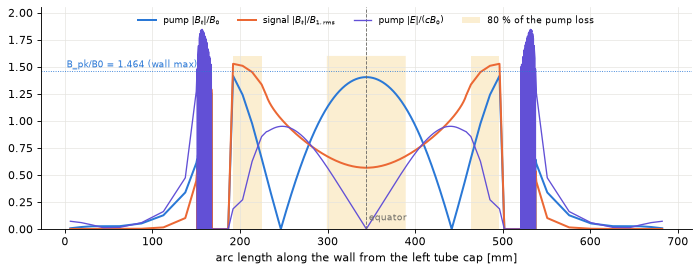

sampled wall max of the pump |B_t|/B0 = 1.4154 (lattice value 1.4640), at the equator 1.4039


In [10]:
def wall_profile(res, row, wall, n_per_seg=4, eps=1e-6 * REQ):
    """Arc length s, (r, z), |B_t| and |E| just inside the wall polyline (both normals tried; the one inside the cavity
    returns finite values)."""
    W = np.asarray(wall, float)
    P, Tn, S, s0 = [], [], [], 0.0
    for p0, p1 in zip(W[:-1], W[1:]):
        L = float(np.hypot(*(p1 - p0)))
        if L == 0:
            continue
        for u in (np.arange(n_per_seg) + 0.5) / n_per_seg:
            P.append(p0 + u * (p1 - p0)); Tn.append((p1 - p0) / L); S.append(s0 + u * L)
        s0 += L
    P, Tn, S = np.array(P), np.array(Tn), np.array(S)
    N = np.column_stack([-Tn[:, 1], Tn[:, 0]])
    best = max((res.cavity_mode_sample(row, *(P + sg * eps * N).T) for sg in (1, -1)),
               key=lambda d: np.isfinite(d["H_phi"]).mean())
    Bt = MU0 * np.sqrt(best["H_phi"] ** 2 + (best["H_r"] * Tn[:, 0] + best["H_z"] * Tn[:, 1]) ** 2)
    E = np.sqrt(best["E_r"] ** 2 + best["E_phi"] ** 2 + best["E_z"] ** 2)
    return S, P, np.nan_to_num(Bt), np.nan_to_num(E)   # points on the axis (cap ends) may fall outside: 0

wall = dcell.srf_contour["wall"]
s_w, P_w, Bt_p, E_p = wall_profile(rcell, pr, wall)
_, _, Bt_s, _ = wall_profile(rcell, sg, wall)
B1rms = fom["signal_peaks"]["B_rms"]
seg = np.linalg.norm(np.diff(np.asarray(wall, float), axis=0), axis=1)
ds = np.repeat(seg[seg > 0] / 4, 4)          # arc length per sample (4 samples per segment)
loss = P_w[:, 0] * Bt_p ** 2 * ds
order = np.argsort(loss)[::-1]
frac = np.cumsum(loss[order]) / loss.sum()
in80 = np.zeros(len(loss), bool); in80[order[: np.searchsorted(frac, 0.8) + 1]] = True
s_eq = s_w[np.argmax(P_w[:, 0])]
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.plot(s_w * 1e3, Bt_p / B0rms, color=BLUE, label=r"pump $|B_t|/B_0$")
ax.plot(s_w * 1e3, Bt_s / B1rms, color=ORANGE, label=r"signal $|B_t|/B_{1,\rm rms}$")
ax.plot(s_w * 1e3, E_p / (C * B0rms), color=VIOLET, lw=1.2, label=r"pump $|E|/(cB_0)$")
ax.fill_between(s_w * 1e3, 0, 1.6, where=in80, color=GOLD, alpha=0.18, lw=0, label="80 % of the pump loss")
ax.axhline(fom["Bpk_over_B0"], color=BLUE, lw=0.8, ls=":")
ax.axvline(s_eq * 1e3, color=GREY, lw=0.8, ls="--")
ax.text(s_eq * 1e3 + 3, 0.08, "equator", color=GREY, fontsize=8)
ax.text(2, fom["Bpk_over_B0"] + 0.03, f"B_pk/B0 = {fom['Bpk_over_B0']:.3f} (wall max)", color=BLUE, fontsize=8)
ax.set_xlabel("arc length along the wall from the left tube cap [mm]"); ax.set_ylim(0, 2.05)
ax.legend(fontsize=8, ncol=4, loc="upper center")
plt.show()
print(f"sampled wall max of the pump |B_t|/B0 = {Bt_p.max() / B0rms:.4f} (lattice value {fom['Bpk_over_B0']:.4f}), "
      f"at the equator {Bt_p[np.argmax(P_w[:, 0])] / B0rms:.4f}")

### Comparison with 3D

We revolve the contour into a cavity to compare 3D and axisymmetric results; this cell needs a build with the 3D engine and STRUMPACK (the 3D shift-invert eigensolver) and runs on four MPI ranks.

  cell_3d_n8_o2: 350852 DOFs, warnings: ['3D eigenmodes: 1 mode(s) within 1e-4 (in k^2) of a returned mode lie just outside the returned window: a near-degenerate pair is cut by the window edge; request more modes to get both members']
3D: 53406 elements; E_phi fraction pump / signal = 4.0e-04 / 0.999538
                  2D (R/40, o3)  3D (R/8, o2)  rel. diff
f TM020 [GHz]          1.416510      1.416585   +5.2e-05
f TE011 [GHz]          1.416531      1.416612   +5.8e-05
xi                     7.642981      7.643365   +5.0e-05
eta_10                 0.449217      0.448883   -7.4e-04
G pump [ohm]         524.474030    524.147070   -6.2e-04
G signal [ohm]       604.478497    603.895223   -9.6e-04
B_pk/B0                1.464004      1.487265   +1.6e-02
E_pk/(c B0)            1.845159      1.783570   -3.3e-02
eta_10 (signal E, pump B) = 0.44888, eta_01 (pump E, signal B) = 0.44887
z = 0 profiles, 3D vs 2D: max |diff| = 0.065 (pump B/B0), 0.026 (signal E/E_rms)


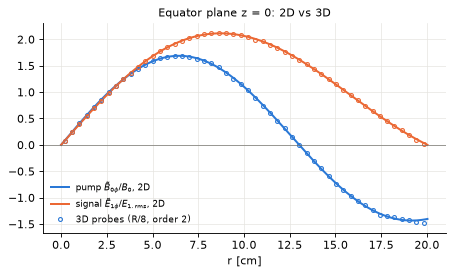

In [11]:
NR = 4                                       # MPI ranks of the 3D solve
RUN_3D = af.build_info()["engine_3d"] and af.build_info()["strumpack"]
if RUN_3D:
    xs = np.linspace(0.01, 0.99, 50) * REQ
    d3 = srf.elliptical_cell_design_3d(CELL, axial_factor=0.86, h=REQ / 8, order=2, modes=16,
                                       target_f_Hz=0.5 * (fom["f_pump_Hz"] + fom["f_signal_Hz"]))
    d3.doc["fullwave"]["field_probes"] = [[float(x), 0.0, 0.0] for x in xs]
    r3 = solve(d3, "cell_3d_n8_o2", mpi_ranks=NR)
    f3 = srf.figures_of_merit_3d(r3, fom["f_pump_Hz"], fom["f_signal_Hz"], contour=d3.srf_contour)
    print(f"3D: {r3.data['mesh'].get('elements')} elements; E_phi fraction pump / signal = "
          f"{f3['E_azimuthal_fraction'][0]:.1e} / {f3['E_azimuthal_fraction'][1]:.6f}")
    print(f"{'':16s}{'2D (R/40, o3)':>15s}{'3D (R/8, o2)':>14s}{'rel. diff':>11s}")
    for lab, k in (("f TM020 [GHz]", "f_pump_Hz"), ("f TE011 [GHz]", "f_signal_Hz"), ("xi", "xi_pump"),
                   ("eta_10", "eta_10"), ("G pump [ohm]", "G_pump_ohm"), ("G signal [ohm]", "G_signal_ohm"),
                   ("B_pk/B0", "Bpk_over_B0"), ("E_pk/(c B0)", "Epk_over_cB0")):
        u = 1e-9 if k.startswith("f_") else 1
        print(f"{lab:16s}{fom[k] * u:15.6f}{f3[k] * u:14.6f}{rel(f3[k], fom[k]):+11.1e}")
    print(f"eta_10 (signal E, pump B) = {f3['eta_10']:.5f}, eta_01 (pump E, signal B) = {f3['eta_01_transpose']:.5f}")
    modes3 = r3.fullwave["eigenmodes"]["modes"]
    mp3, ms3 = modes3[f3["i_pump"]], modes3[f3["i_signal"]]
    B3 = np.array(mp3["probes"]["B"])[:, 1] / mp3["peak_wall_fields"]["B_rms"]           # B_y = B_phi on the +x axis
    E3 = np.array(ms3["probes"]["E"])[:, 1] * math.sqrt(r3.fullwave["cavity"]["volume_m3"])  # int |E|^2 = 1
    B3 *= np.sign(np.dot(B3, np.interp(xs, rr, Bl))); E3 *= np.sign(np.dot(E3, np.interp(xs, rr, El)))
    print(f"z = 0 profiles, 3D vs 2D: max |diff| = {np.abs(B3 - np.interp(xs, rr, Bl)).max():.3f} (pump B/B0), "
          f"{np.abs(E3 - np.interp(xs, rr, El)).max():.3f} (signal E/E_rms)")
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.plot(rr * 100, Bl, color=BLUE, label=r"pump $\tilde B_{0\phi}/B_0$, 2D")
    ax.plot(rr * 100, El, color=ORANGE, label=r"signal $\tilde E_{1\phi}/E_{1,\rm rms}$, 2D")
    ax.plot(xs * 100, B3, "o", color=BLUE, ms=3.5, mfc="none", label="3D probes (R/8, order 2)")
    ax.plot(xs * 100, E3, "o", color=ORANGE, ms=3.5, mfc="none")
    ax.axhline(0, color=GREY, lw=0.6); ax.set_xlabel("r [cm]"); ax.set_title("Equator plane z = 0: 2D vs 3D", fontsize=10)
    ax.legend(fontsize=8); plt.show()
else:
    print("3D cross-check skipped: this build has no 3D engine with STRUMPACK")

The 3D surface mesh should be refined before using its wall peaks or losses. When the eigensolver warns that a returned mode has a near-degenerate partner just outside the requested window, requesting more modes (`modes=` of `elliptical_cell_design_3d`) returns both members. The pump and signal are the returned modes with the required field pattern (azimuthal-E fraction below 0.01 or above 0.99) closest to the axisymmetric frequencies at the centre of the window, so a mode outside the window does not change them.

## Sensitivity

`het.SRFGeometry.from_modes` passes mode properties to the scan model. On resonance, for an axion line narrower than the signal linewidth,

$$
P_{\rm sig}=\frac14 g^2\eta^2 B_0^2\rho V\frac{Q_1}{\omega_1}.
$$

This uses natural Heaviside–Lorentz units: $g$ is axion–photon coupling, $\rho$ axion density, $\eta$ the overlap above, and $Q_1$ the loaded signal quality factor at angular frequency $\omega_1$. Python uses SI, with coupling in GeV$^{-1}$ and density in GeV/cm$^3$.

We compare the geometry parameters from the solved modes with the cached preset of the same cell.

In [12]:
geos = {"this solve, B_pk wall": het.SRFGeometry.from_modes(fom, bpk="wall", name="notebook, wall"),
        "preset PROJECTX_086": het.PROJECTX_086}
print(f"{'':27s}{'xi':>8s}{'eta':>8s}{'G0':>8s}{'G1':>8s}{'Bpk/B0':>8s}{'A/V^2/3':>9s}{'Epk/cB0':>9s}")
for k, g in geos.items():
    print(f"{k:27s}{g.xi:8.4f}{g.eta:8.4f}{g.G_pump_ohm:8.2f}{g.G_signal_ohm:8.2f}{g.Bpk_over_B0:8.4f}{g.area_coeff:9.4f}"
          f"{g.Epk_over_cB0:9.4f}")

                                 xi     eta      G0      G1  Bpk/B0  A/V^2/3  Epk/cB0
this solve, B_pk wall        7.6430  0.4492  524.47  604.48  1.4640   6.1822   1.8452
preset PROJECTX_086          7.6430  0.4492  524.47  604.48  1.4640   6.1822   1.8431


### Scan rate and scan time of a cavity

`het.ScenarioA` holds what the scan model needs besides the geometry: the surface resistance $R_s$, the peak wall field $B_{\rm pk}$ (which sets $B_0=B_{\rm pk}/(B_{\rm pk}/B_0)$), the flat receiver noise $A$ in quanta, and the wall temperature, which sets the wall's thermal occupation. `het.Target` holds the band, the coupling model (DFSZ by default), the live time and the halo parameters. The values below are round, illustrative numbers, not a proposed experiment: replace them with the parameters of the cavity, readout and search under study. `het.SCENARIOS_A` holds two more presets of the same form, also illustrative.

We scale the solved cell to three volumes and compute, for each, the frequency, the RF load and the time the scan needs to cover the band; then the smallest volume that covers it in the live time.

In [13]:
geo = geos["this solve, B_pk wall"]
sc = het.ScenarioA("illustrative", Rs_ohm=10e-9, Bpk_T=0.10, A=2.0, T_K=2.0, geometry=geo)
band = het.Target(f_min_Hz=0.2e6, f_max_Hz=2.0e6, live_time_yr=1.0)        # an illustrative band and live time
print(f"scenario: R_s = {sc.Rs_ohm * 1e9:g} nOhm, B_pk = {sc.Bpk_T * 1e3:g} mT (B0 = {sc.B0_T * 1e3:.1f} mT), A = {sc.A:g}, "
      f"T = {sc.T_K:g} K;  band {band.f_min_Hz / 1e3:g} kHz - {band.f_max_Hz / 1e6:g} MHz ({band.model}), "
      f"live time {band.live_time_yr:g} yr")


def rate_fn(V):
    "Weak-signal scan rate [Hz/s] of the scaled cell of volume V, coupling optimal at every mass."
    f0 = float(geo.f0_Hz(V))

    def rate(f_a):
        f1 = f0 + np.asarray(f_a, float)
        return het.scan_rate(f_a, f1, V, sc.B0_T, geo.eta, geo.G_signal_ohm / sc.Rs(f1), sc.A,
                             het.occupation(f1, sc.T_K), target=band)
    return rate


VOLS = (100.0, 1000.0, 10000.0)
print(f"\n{'V [m^3]':>8s}{'f0 [MHz]':>10s}{'R_eq [m]':>10s}{'Q0':>10s}{'U0 [kJ]':>9s}{'P_RF [W]':>10s}"
      f"{'rate at band ends [Hz/s]':>27s}{'scan time [yr]':>16s}")
for V in VOLS:
    f0 = float(geo.f0_Hz(V))
    Q0 = geo.G_pump_ohm / sc.Rs(f0)
    U0 = sc.B0_T ** 2 * V / (2 * MU0)
    r_lo, r_hi = rate_fn(V)(np.array([band.f_min_Hz, band.f_max_Hz]))
    t = het.scan_time(rate_fn(V), band.f_min_Hz, band.f_max_Hz)
    print(f"{V:8.0f}{f0 / 1e6:10.2f}{REQ * (V / fom['V_m3']) ** (1 / 3):10.2f}{Q0:10.2e}{U0 / 1e3:9.1f}"
          f"{2 * math.pi * f0 * U0 / Q0:10.2f}{r_lo:14.3g} / {r_hi:<10.3g}{t / het.YEAR:16.3g}")

V_req = het.required_volume(sc, band)
print(f"\nsmallest volume that covers the band in {band.live_time_yr:g} yr: V = {V_req:.2f} m^3 "
      f"(f0 = {geo.f0_Hz(V_req) / 1e6:.1f} MHz, equator radius {REQ * (V_req / fom['V_m3']) ** (1 / 3):.2f} m)")
print("check: the scan rate grows as V^(8/3) at fixed xi in the n_i >> 1 limit "
      f"(het.volume_scaling_exponents()['rate_V'] = {het.volume_scaling_exponents()['rate_V']:.4f})")

scenario: R_s = 10 nOhm, B_pk = 100 mT (B0 = 68.3 mT), A = 2, T = 2 K;  band 200 kHz - 2 MHz (DFSZ), live time 1 yr

 V [m^3]  f0 [MHz]  R_eq [m]        Q0  U0 [kJ]  P_RF [W]   rate at band ends [Hz/s]  scan time [yr]
     100     78.57      3.61  5.24e+10    185.6   1747.30      3.31e-06 / 0.00316                952
    1000     36.47      7.78  5.24e+10   1856.4   8110.27       0.00153 / 1.39                  2.07
   10000     16.93     16.76  5.24e+10  18564.2  37644.54           0.7 / 574                0.00457

smallest volume that covers the band in 1 yr: V = 1315.05 m^3 (f0 = 33.3 MHz, equator radius 8.52 m)
check: the scan rate grows as V^(8/3) at fixed xi in the n_i >> 1 limit (het.volume_scaling_exponents()['rate_V'] = 2.6667)


The RF load is that of the pump mode alone: it excludes static heat, and the model omits field-dependent surface resistance, pump-induced signal loss and field-emission loads.

### Signal statistics

The weak-signal rate assumes a per-bin signal/background $\lambda_a/\lambda_B \ll 1$. `het.peak_bin_snr` gives the largest per-bin ratio, and `het.required_volume_exact` repeats the sizing with the exact (Asimov) statistic, the coupling re-optimised at every mass.

In [14]:
snr_ends = het.peak_bin_snr(sc, V_req, np.array([band.f_min_Hz, band.f_max_Hz]), target=band)
ex = het.required_volume_exact(sc, band, n_f=16)
print(f"weak-signal sizing: V = {V_req:.3f} m^3; peak per-bin lambda_a/lambda_B at the band ends "
      f"{snr_ends[0]:.3f} / {snr_ends[1]:.3f}")
print(f"exact statistic:    V = {ex['V_m3']:.3f} m^3 (x {ex['V_m3'] / V_req:.4f}); peak lambda_a/lambda_B "
      f"{ex['peak_bin_snr_ends'][0]:.3f} / {ex['peak_bin_snr_ends'][1]:.3f}; coupling beta at the band ends "
      f"{ex['beta_ends'][0]:.0f} / {ex['beta_ends'][1]:.0f}")

weak-signal sizing: V = 1315.051 m^3; peak per-bin lambda_a/lambda_B at the band ends 0.255 / 2.418
exact statistic:    V = 1502.667 m^3 (x 1.1427); peak lambda_a/lambda_B 0.283 / 1.841; coupling beta at the band ends 1601 / 3321


### Scan tracking

`het.scan_rate` gives Hz/s; integrating the inverse rate across the band gives the scan time. We compare the rate with the resonance-tracking (adiabatic) limit for the three volumes, and size the scan again with the coupling raised where the limit binds.

V =   100 m^3: rate / adiabatic limit 5.18e-05 -> 0.0211; below the limit across the band
V =  1000 m^3: rate / adiabatic limit 0.024 -> 9.27; above the limit from 940 kHz
V = 10000 m^3: rate / adiabatic limit 11 -> 3.84e+03; above the limit from 200 kHz
with the adiabatic schedule (beta raised where the limit binds): V = 1317.395 m^3 (+0.18 % against the weak-signal sizing)


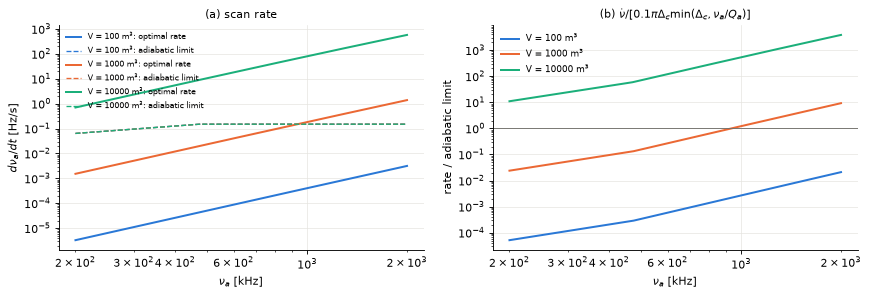

In [15]:
fa = np.geomspace(band.f_min_Hz, band.f_max_Hz, 300)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 3.8))
for V, col in zip(VOLS, (BLUE, ORANGE, GREEN)):
    f1 = float(geo.f0_Hz(V)) + fa
    Qi = geo.G_signal_ohm / sc.Rs(f1)
    beta = het.beta_opt(sc.A, het.occupation(f1, sc.T_K))
    rate = rate_fn(V)(fa)
    track = het.tracking_rate(beta, fa, f1, Qi, 0.1)
    ax0.loglog(fa / 1e3, rate, color=col, label=f"V = {V:g} m$^3$: optimal rate")
    ax0.loglog(fa / 1e3, track, color=col, ls="--", lw=1.2, label=f"V = {V:g} m$^3$: adiabatic limit")
    ax1.loglog(fa / 1e3, rate / track, color=col, label=f"V = {V:g} m$^3$")
    above = fa[rate > track]
    print(f"V = {V:5g} m^3: rate / adiabatic limit {rate[0] / track[0]:.3g} -> {rate[-1] / track[-1]:.3g}"
          + (f"; above the limit from {above[0] / 1e3:.0f} kHz" if above.size else "; below the limit across the band"))
ax0.set_ylabel(r"$d\nu_a/dt$ [Hz/s]"); ax0.set_title("(a) scan rate", fontsize=10); ax0.legend(fontsize=7)
ax1.axhline(1, color=GREY, lw=0.8); ax1.set_ylabel("rate / adiabatic limit")
ax1.set_title(r"(b) $\dot\nu/[0.1\pi\Delta_c\min(\Delta_c,\nu_a/Q_a)]$", fontsize=10); ax1.legend(fontsize=8)
for ax in (ax0, ax1):
    ax.set_xlabel(r"$\nu_a$ [kHz]")
fig.tight_layout(); plt.show()

V_ad = het.required_volume(sc, band, adiabatic_eps=0.1)
print(f"with the adiabatic schedule (beta raised where the limit binds): V = {V_ad:.3f} m^3 "
      f"({100 * rel(V_ad, V_req):+.2f} % against the weak-signal sizing)")

Ratios above unity exceed tracking. Exact statistics and tracking are imposed separately here; `adiabatic_eps=0.1` should be combined with `het.required_volume_exact` when both matter. `guard_Hz` extends the scan beyond the band ends so that the end masses see the whole response; these scans are unguarded.

## Vibration requirement

Wall motion at the splitting frequency can scatter pump energy into the signal mode. For an axisymmetric cavity, the pump and signal fields have orthogonal components, so first-order wall-displacement mixing vanishes; static departures from roundness allow mixing. For isotropic random errors and a diffuse vibration field,

$$
\eta_{\rm mix}=c_{\rm eff}\frac{\delta_s}{R_{\rm eq}},\qquad
c_{\rm eff}=(\ln2)^{-1/2}R_{\rm eq}L_c\sqrt{\pi I_4},\qquad
I_4=\oint(B_{0t}B_{1t})^2\,dA.
$$

Here $R_{\rm eq}$ is the equator radius, $L_c=V^{1/3}$, and $\delta_s$ is rms out-of-roundness per octave at the vibration's elastic wavenumber. The tangential wall fields use $\int|\mathbf B|^2dV=1$ for each mode. The helper functions come from `benchmarks/srf/srf_vibration_mixing.py` in a source checkout, which also computes the coherent 3D deformations discussed in the [vibration notes](../docs/srf/vibrations.md).

We check which field components of the two modes are nonzero.

In [16]:
import importlib.util

_spec = importlib.util.spec_from_file_location("srf_vibration_mixing", ROOT / "benchmarks/srf/srf_vibration_mixing.py")
vm = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(vm)

print(f"{'max |component| / max |field|':32s}{'E_r':>9s}{'E_phi':>9s}{'E_z':>9s}{'H_r':>9s}{'H_phi':>9s}{'H_z':>9s}")
for name, F in (("pump TM020", Fp), ("signal TE011", Fs)):
    Em = max(np.abs(F[k]).max() for k in ("E_r", "E_phi", "E_z"))
    Hm = max(np.abs(F[k]).max() for k in ("H_r", "H_phi", "H_z"))
    print(f"{name:32s}" + "".join(f"{np.abs(F[k]).max() / (Em if k[0] == 'E' else Hm):9.1e}"
                                   for k in ("E_r", "E_phi", "E_z", "H_r", "H_phi", "H_z")))
BB = Fp["H_r"] * Fs["H_r"] + Fp["H_phi"] * Fs["H_phi"] + Fp["H_z"] * Fs["H_z"]
EE = Fp["E_r"] * Fs["E_r"] + Fp["E_phi"] * Fs["E_phi"] + Fp["E_z"] * Fs["E_z"]
print(f"\npointwise max |H0.H1| / max(|H0||H1|) = {np.abs(BB).max() / (Fp['Hmag'] * Fs['Hmag']).max():.1e}, "
      f"max |E0.E1| / max(|E0||E1|) = {np.abs(EE).max() / (Fp['Emag'] * Fs['Emag']).max():.1e}")

max |component| / max |field|         E_r    E_phi      E_z      H_r    H_phi      H_z
pump TM020                        5.7e-01  0.0e+00  1.0e+00  0.0e+00  1.0e+00  0.0e+00
signal TE011                      0.0e+00  1.0e+00  0.0e+00  5.9e-01  0.0e+00  1.0e+00

pointwise max |H0.H1| / max(|H0||H1|) = 0.0e+00, max |E0.E1| / max(|E0||E1|) = 0.0e+00


The zero components explain why the two field dot products vanish. The next cell integrates the wall fields to obtain $c_{\rm eff}$ for the mode solve above (cell size $R_{\rm eq}/40$, order 3).

In [17]:
res, pump, sig, con = rcell, pr, sg, dcell.srf_contour
N = 40
V = res.fullwave["cavity"]["volume_m3"]
Lc = V ** (1 / 3)
norm = {}
for nm, row in (("pump", pump), ("signal", sig)):
    F = rcell.cavity_mode_field(row, subdiv=4)
    norm[nm] = sum(srf._tri_product_integral(F["r"], F["z"], F["tris"], MU0 * F[k], MU0 * F[k])
                   for k in ("H_r", "H_phi", "H_z"))                     # int |B|^2 dV at the solver normalization
P, T, Lseg = vm._wall_points(con["wall"])                                # wall samples, tangents, segment lengths
B0t = vm._tangential_B(res, pump, P, T, "TM") / math.sqrt(norm["pump"])
B1t = vm._tangential_B(res, sig, P, T, "TE") / math.sqrt(norm["signal"])
dA = 2 * math.pi * P[:, 0] * Lseg
I4 = float(np.sum((B0t * B1t) ** 2 * dA))
per_oct = 1 / math.sqrt(math.log(2))
c_eff = per_oct * REQ * Lc * math.sqrt(math.pi * I4)
c_Gavg = per_oct * REQ * Lc * math.sqrt(math.pi * np.sum(B0t ** 2 * dA) * np.sum(B1t ** 2 * dA) / np.sum(dA))
print(f"wall area {dA.sum():.4f} m^2 ({len(P)} samples), L_c = {Lc:.4f} m, R_eq = {REQ} m, I_4 = {I4:.1f} m^-4")
print(f"c_eff (h = R_eq/{N}) = {c_eff:.4f};  G-average closed form = {c_Gavg:.4f}")

wall area 0.4097 m^2 (2360 samples), L_c = 0.2574 m, R_eq = 0.2003 m, I_4 = 1159.6 m^-4
c_eff (h = R_eq/40) = 3.7383;  G-average closed form = 3.4068


The cumulative curve locates the wall regions contributing most to $I_4$.

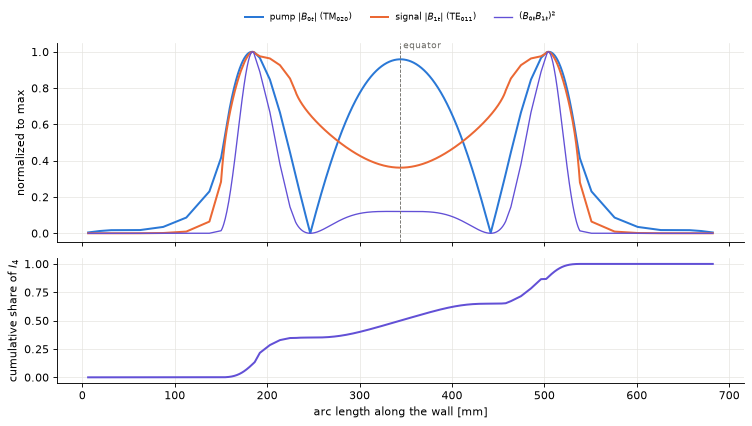

share of I_4: equator band between the pump's wall nodes 0.30, iris-side bands 0.70, beam tubes 5.4e-05 (doc: tubes 5.4e-5)


In [18]:
s = np.concatenate([[0.0], np.cumsum(Lseg)])[:-1] + 0.5 * Lseg            # arc length of each sample
q = (B0t * B1t) ** 2 * dA
eq = np.argmax(P[:, 0])
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(9.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
ax0.plot(s * 1e3, B0t / np.abs(B0t).max(), color=BLUE, label=r"pump $|B_{0t}|$ (TM$_{020}$)")
ax0.plot(s * 1e3, B1t / np.abs(B1t).max(), color=ORANGE, label=r"signal $|B_{1t}|$ (TE$_{011}$)")
ax0.plot(s * 1e3, (B0t * B1t) ** 2 / ((B0t * B1t) ** 2).max(), color=VIOLET, lw=1.2, label=r"$(B_{0t}B_{1t})^2$")
ax0.axvline(s[eq] * 1e3, color=GREY, lw=0.8, ls="--"); ax0.text(s[eq] * 1e3 + 3, 1.02, "equator", fontsize=8, color=GREY)
ax0.set_ylabel("normalized to max"); ax0.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.2))
ax1.plot(s * 1e3, np.cumsum(q) / q.sum(), color=VIOLET)
ax1.set_ylabel("cumulative share of $I_4$"); ax1.set_xlabel("arc length along the wall [mm]")
fig.tight_layout(); plt.show()
tube = np.abs(P[:, 1]) > con["z_end"] - con["params"]["tube_length"] + 1e-12
nodes = np.flatnonzero((B0t / B0t.max() < 0.05) & (P[:, 0] > 0.5 * REQ))     # the pump's wall nodes beside the equator
band = np.zeros(len(q), bool); band[nodes.min():nodes.max() + 1] = True
print(f"share of I_4: equator band between the pump's wall nodes {q[band].sum() / q.sum():.2f}, iris-side bands "
      f"{q[~band & ~tube].sum() / q.sum():.2f}, beam tubes {q[tube].sum() / q.sum():.1e} (doc: tubes 5.4e-5)")

## Displacement-noise limit

To keep vibration noise below a fraction $\epsilon$ of thermal noise, require

$$
S_u^{1/2}\le\frac{2\sqrt2\,L_c}{\eta_{\rm mix}}
\left(\frac{\epsilon n_i\hbar}{U_0Q_i}\right)^{1/2}.
$$

Here $n_i$ is the wall's thermal occupation at the pump frequency, $U_0=B_0^2V/(2\mu_0)$ is pump energy, and $Q_i=G_{\rm signal}/R_s$ is signal quality factor. The next cell evaluates the limit at unit mixing for the illustrative scenario and the three volumes above.

In [19]:
EPS = 0.1
C_EFF = c_eff                                             # from the integral above


def requirement(sc, V):
    "S_u^(1/2) at eta_mix = 1 [m/sqrt(Hz)] of scenario sc at volume V."
    f0 = float(sc.geometry.f0_Hz(V))
    n_i = float(het.occupation(f0, sc.T_K))
    U0 = sc.B0_T ** 2 * V / (2 * MU0)
    Qi = sc.geometry.G_signal_ohm / sc.Rs(f0)
    return 2 * math.sqrt(2) * V ** (1 / 3) * math.sqrt(EPS * n_i * HBAR / (U0 * Qi)), f0, n_i, Qi


res_req = {}
print(f"{'V [m^3]':>8s}{'f0 [MHz]':>10s}{'n_i':>8s}{'Q_i':>10s}{'R_eq [m]':>10s}{'S_u^1/2 (eta=1) [m/sqrt(Hz)]':>31s}")
for V in VOLS:
    S1, f0, n_i, Qi = requirement(sc, V)
    R_eq = REQ * (V / fom["V_m3"]) ** (1 / 3)
    res_req[V] = (S1, R_eq)
    print(f"{V:8.0f}{f0 / 1e6:10.2f}{n_i:8.0f}{Qi:10.2e}{R_eq:10.2f}{S1:31.3e}")

 V [m^3]  f0 [MHz]     n_i       Q_i  R_eq [m]   S_u^1/2 (eta=1) [m/sqrt(Hz)]
     100     78.57     530  6.04e+10      3.61                      9.265e-24
    1000     36.47    1142  6.04e+10      7.78                      9.267e-24
   10000     16.93    2461  6.04e+10     16.76                      9.268e-24


In the high-occupation regime ($n_i \approx k_BT/h f_0 \gg 1$), $n_i/U_0 \propto 1/(f_0 V) \propto V^{-2/3}$ at fixed $B_0$ and $R_s$, which cancels the $V^{1/3}$ of $L_c$: the limit at unit mixing barely changes with volume.

In [20]:
S_ref = res_req[VOLS[1]][0]
for V in VOLS:
    print(f"V = {V:5g} m^3: S_u^1/2(eta = 1) / its value at {VOLS[1]:g} m^3 = {res_req[V][0] / S_ref:.5f}")

V =   100 m^3: S_u^1/2(eta = 1) / its value at 1000 m^3 = 0.99975
V =  1000 m^3: S_u^1/2(eta = 1) / its value at 1000 m^3 = 1.00000
V = 10000 m^3: S_u^1/2(eta = 1) / its value at 1000 m^3 = 1.00012


The final plot includes the mixing coefficient: better roundness permits larger displacement noise at the scan frequency. The mixing grows with the equator radius at fixed $\delta_s$ only through $\delta_s/R_{\rm eq}$, so a larger cell tolerates a larger absolute out-of-roundness.

V =   100 m^3: R_eq = 3.61 m;  S_u^1/2 at delta_s = 1 um: 8.95e-18 m/sqrt(Hz) (c_eff = 3.738)
V =  1000 m^3: R_eq = 7.78 m;  S_u^1/2 at delta_s = 1 um: 1.93e-17 m/sqrt(Hz) (c_eff = 3.738)
V = 10000 m^3: R_eq = 16.76 m;  S_u^1/2 at delta_s = 1 um: 4.16e-17 m/sqrt(Hz) (c_eff = 3.738)


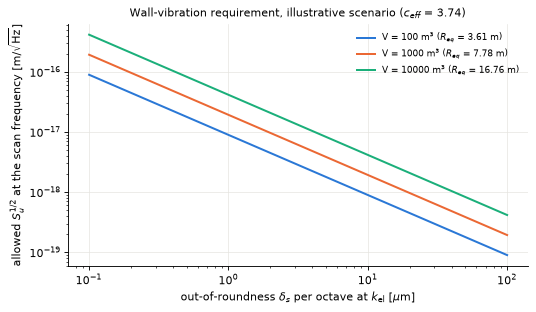

In [21]:
ds = np.geomspace(0.1e-6, 100e-6, 100)
fig, ax = plt.subplots(figsize=(6.8, 4.0))
for V, col in zip(VOLS, (BLUE, ORANGE, GREEN)):
    S1, R_eq = res_req[V]
    S = S1 * R_eq / (C_EFF * ds)
    print(f"V = {V:5g} m^3: R_eq = {R_eq:.2f} m;  S_u^1/2 at delta_s = 1 um: {S1 * R_eq / (C_EFF * 1e-6):.2e} m/sqrt(Hz) "
          f"(c_eff = {C_EFF:.3f})")
    ax.loglog(ds * 1e6, S, color=col, label=f"V = {V:g} m$^3$ ($R_{{eq}}$ = {R_eq:.2f} m)")
ax.set_xlabel(r"out-of-roundness $\delta_s$ per octave at $k_{\rm el}$ [$\mu$m]")
ax.set_ylabel(r"allowed $S_u^{1/2}$ at the scan frequency [m/$\sqrt{\rm Hz}$]")
ax.set_title(f"Wall-vibration requirement, illustrative scenario ($c_{{eff}}$ = {C_EFF:.2f})", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

The random-error model assumes diffuse vibrations. Coherent deformations that break the cell's mirror symmetry, such as a twisted ellipse, are treated in 3D in the [vibration notes](../docs/srf/vibrations.md).

See also the [SRF guide](../docs/srf/README.md), the [sensitivity notes](../docs/srf/sensitivity.md) and the [heterodyne API](../docs/api.md).